<a href="https://colab.research.google.com/github/MuhammadSahlanHabibi/Introduction-to-Machine-Learning/blob/main/Network_Anomaly_Detection_using_Isolation_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Memulai pemodelan Machine Learning (Anomaly Detection)...

Dataset berhasil dimuat dengan total 420 sampel data.

=== HASIL DETEKSI ANOMALI ===
Jumlah data normal terdeteksi : 399
Jumlah anomali/lonjakan ekstrem: 21 data



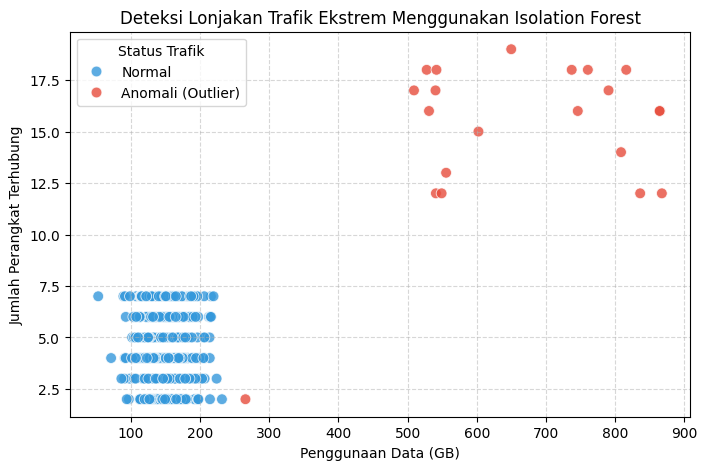

In [1]:
# ==============================================================================
# IMPLEMENTASI SEMINAR 4: INTRODUCTION TO MACHINE LEARNING
# Topik: Deteksi Anomali Jaringan / Lonjakan Trafik Ekstrem (Isolation Forest)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

print("Memulai pemodelan Machine Learning (Anomaly Detection)...\n")

# ==============================================================================
# 1. GENERASI DATASET OPERASIONAL (Trafik Wi-Fi / Penggunaan Bulanan)
# ==============================================================================
np.random.seed(42)
n_samples = 400

# Simulasi data normal penggunaan data (GB) dan jumlah perangkat terhubung
normal_usage = np.random.normal(loc=150, scale=30, size=n_samples)
normal_devices = np.random.randint(2, 8, size=n_samples)

# Sengaja menyisipkan 20 data anomali (lonjakan ekstrem / gangguan jaringan tidak wajar)
anomaly_usage = np.random.uniform(500, 900, 20)
anomaly_devices = np.random.randint(12, 20, 20)

# Menggabungkan data
total_usage = np.concatenate([normal_usage, anomaly_usage])
total_devices = np.concatenate([normal_devices, anomaly_devices])

df_ml = pd.DataFrame({
    'Penggunaan_GB': total_usage,
    'Jumlah_Perangkat': total_devices
})

print(f"Dataset berhasil dimuat dengan total {len(df_ml)} sampel data.\n")

# ==============================================================================
# 2. TRAINING MODEL MACHINE LEARNING (ISOLATION FOREST)
# ==============================================================================
# Menggunakan Isolation Forest untuk mendeteksi outlier/anomali secara otomatis
iso_forest = IsolationForest(contamination=0.05, random_state=42)
df_ml['Anomali_Score'] = iso_forest.fit_predict(df_ml[['Penggunaan_GB', 'Jumlah_Perangkat']])

# Konversi label: 1 = Normal, -1 = Anomali / Outlier
df_ml['Status'] = df_ml['Anomali_Score'].map({1: 'Normal', -1: 'Anomali (Outlier)'})

jumlah_anomali = (df_ml['Status'] == 'Anomali (Outlier)').sum()
print(f"=== HASIL DETEKSI ANOMALI ===")
print(f"Jumlah data normal terdeteksi : {len(df_ml) - jumlah_anomali}")
print(f"Jumlah anomali/lonjakan ekstrem: {jumlah_anomali} data\n")

# ==============================================================================
# 3. VISUALISASI HASIL MACHINE LEARNING
# ==============================================================================
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_ml,
    x='Penggunaan_GB',
    y='Jumlah_Perangkat',
    hue='Status',
    palette={'Normal': '#3498db', 'Anomali (Outlier)': '#e74c3c'},
    alpha=0.8,
    s=60
)

plt.title('Deteksi Lonjakan Trafik Ekstrem Menggunakan Isolation Forest')
plt.xlabel('Penggunaan Data (GB)')
plt.ylabel('Jumlah Perangkat Terhubung')
plt.legend(title='Status Trafik')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()